In [1]:
import xarray as xr
import scipy
import numpy as np
import matplotlib.pyplot as plt

In [2]:
ds = xr.open_dataset("/home/has/data/sources/icon/ICON312_v1.0.0.zarr")
data = ds.isel(time=400)

In [3]:
variables = ["t_2m", "u_10m", "v_10m", "qv_2m", "tqc_dia", "rain_gsp_rate"] #, "lhfl_s", "shfl_s", "sob_t", "thb_t"]

In [7]:
raw_distributions = {}
raw_stats = {}
for var in variables:
    values = np.asarray(data[var].values).ravel()
    values = values[np.isfinite(values)]
    raw_distributions[var] = np.histogram(values, bins=50, density=True)
    raw_stats[var] = {"mean": np.mean(values), "std": np.std(values)}

z_score_distributions = {}
z_score_stats = {}
for var in variables:
    values = np.asarray(data[var].values).ravel()
    values = values[np.isfinite(values)]
    mean = np.mean(values)
    std = np.std(values)
    z_scores = (values - mean) / std
    z_score_distributions[var] = np.histogram(z_scores, bins=50, density=True)
    z_score_stats[var] = {"mean": np.mean(z_scores), "std": np.std(z_scores)}

transformed_distributions = {}
transformed_stats = {}
for var in variables:
    if var == "tqc_dia":
        lmbda = 0.0673 # is approx 1/15 and the optimal lambda for positive values
    elif var == "rain_gsp_rate":
        lmbda = -0.0690
    else:
        continue
    values = np.asarray(data[var].values).ravel()
    values = values[np.isfinite(values)]
    # if var == "rain_gsp_rate":
    #     values = values[values > 0]
    transformed_values = boxcox_transform(values[values > 0], lmbda)
    transformed_distributions[var] = np.histogram(transformed_values, bins=50, density=True)
    transformed_stats[var] = {"mean": np.mean(transformed_values), "std": np.std(transformed_values)}
    # print(f"{var}: Box-Cox lambda = {lmbda:.4f}")

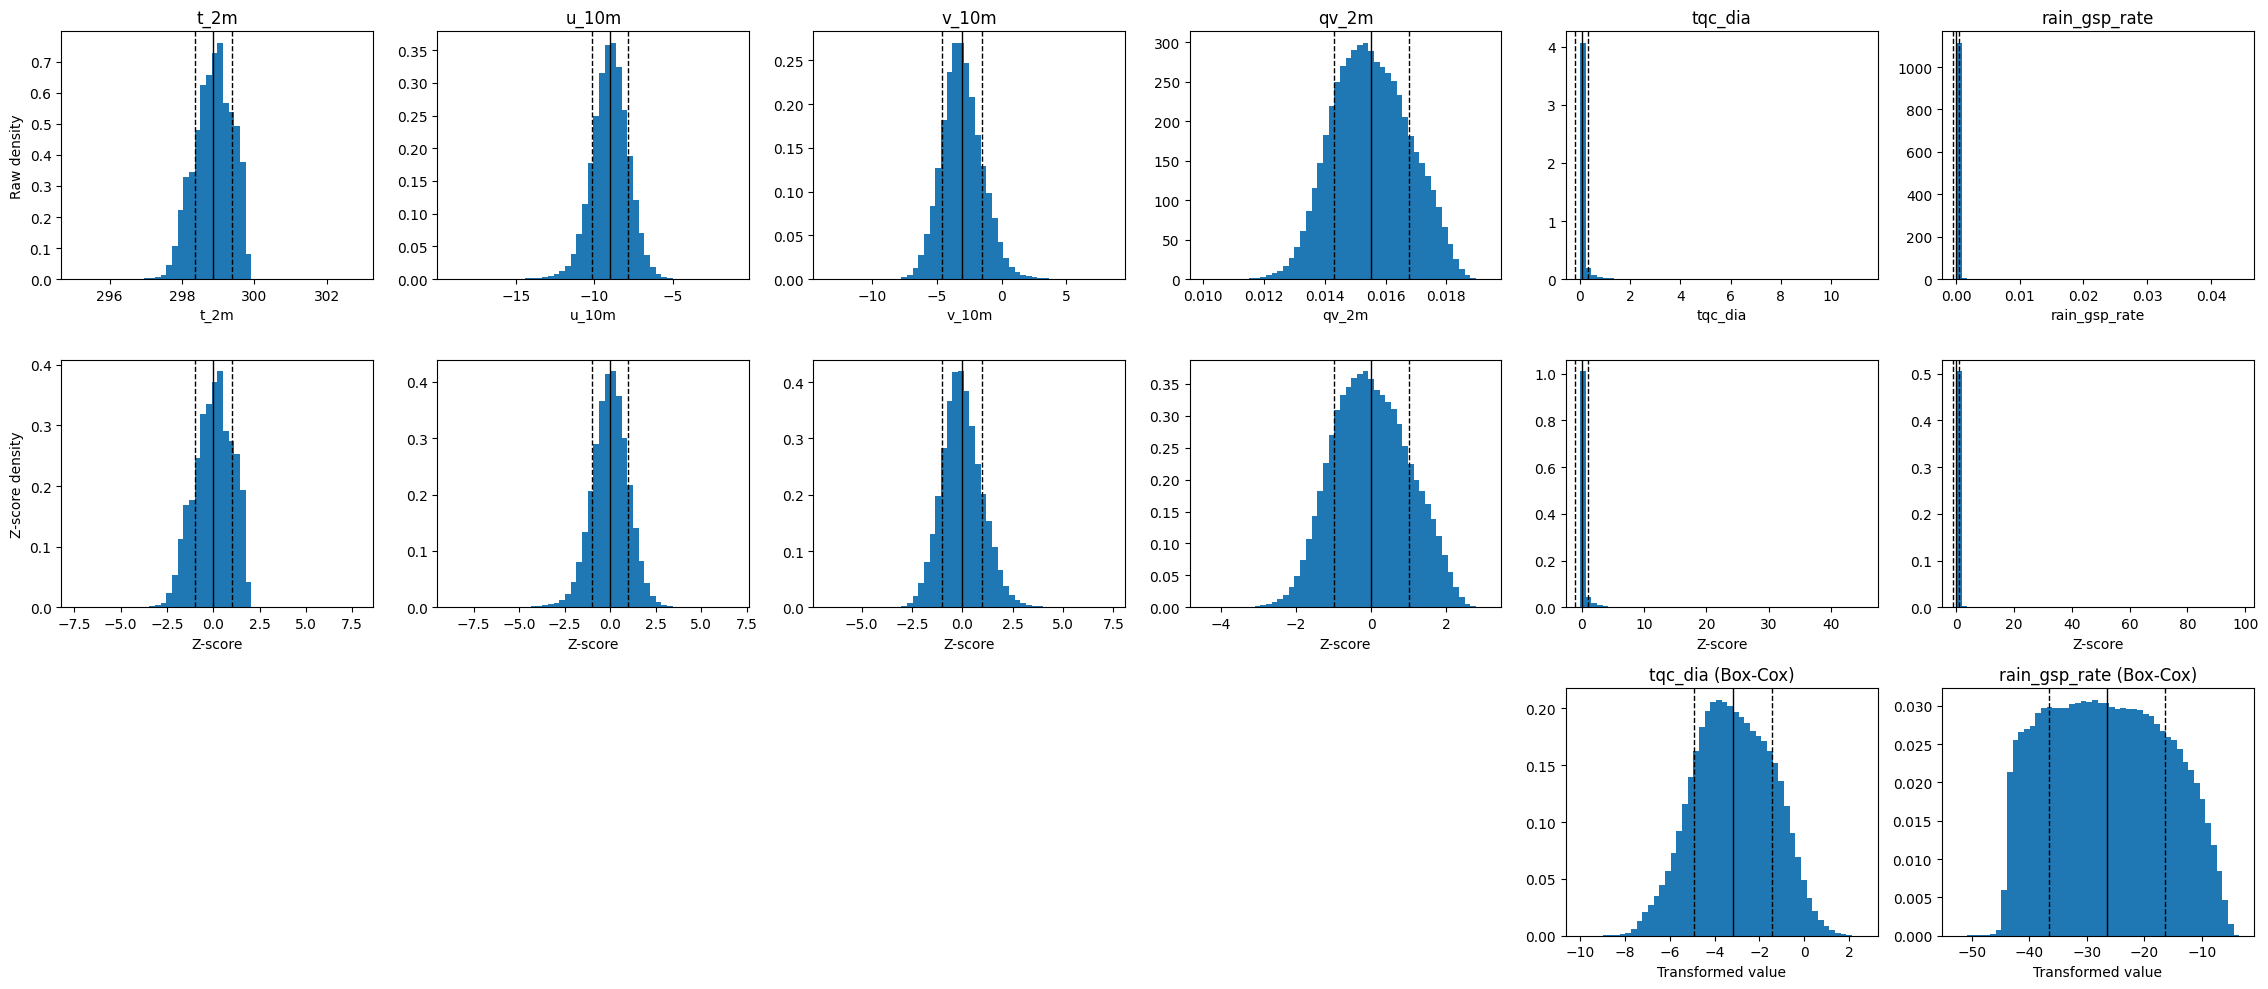

In [8]:
# Plotting the distributions (columns: variables, rows: distribution types)
fig, axes = plt.subplots(3, len(variables), figsize=(3.8 * len(variables), 10), squeeze=False)

def add_mean_std_lines(ax, stats):
    mean = stats["mean"]
    std = stats["std"]
    ax.axvline(mean, color='black', linestyle='-', linewidth=1)
    ax.axvline(mean - std, color='black', linestyle='--', linewidth=1)
    ax.axvline(mean + std, color='black', linestyle='--', linewidth=1)

def apply_y_axis_cut(ax, heights, min_peak_ratio=6.0):
    # Cut the y-axis when a single dominant bin hides the rest of the distribution.
    if len(heights) < 2:
        return

    sorted_heights = np.sort(heights)
    peak = sorted_heights[-1]
    second_peak = sorted_heights[-2]

    if second_peak <= 0 or peak / second_peak < min_peak_ratio:
        return

    y_cut = second_peak * 1.25
    y_cut = min(y_cut, peak * 0.9)
    ax.set_ylim(0, y_cut)

    # Draw y-axis break markers at the top of the axis.
    d = 0.015
    kwargs = dict(transform=ax.transAxes, color='black', clip_on=False, linewidth=1)
    ax.plot((-d, +d), (1 - d, 1 + d), **kwargs)
    ax.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)
    ax.text(
        0.02,
        0.97,
        f'peak={peak:.2f}',
        transform=ax.transAxes,
        va='top',
        ha='left',
        fontsize=8,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85, edgecolor='none'),
    )

for i, var in enumerate(variables):
    # Raw distribution (row 0)
    axes[0, i].bar(
        raw_distributions[var][1][:-1],
        raw_distributions[var][0],
        width=np.diff(raw_distributions[var][1]),
        align='edge',
    )
    axes[0, i].set_title(var)
    axes[0, i].set_xlabel(var)
    axes[0, i].set_ylabel('Density' if i == 0 else '')
    add_mean_std_lines(axes[0, i], raw_stats[var])

    # Z-score distribution (row 1)
    axes[1, i].bar(
        z_score_distributions[var][1][:-1],
        z_score_distributions[var][0],
        width=np.diff(z_score_distributions[var][1]),
        align='edge',
    )
    axes[1, i].set_xlabel('Z-score')
    axes[1, i].set_ylabel('Density' if i == 0 else '')
    add_mean_std_lines(axes[1, i], z_score_stats[var])

    # Transformed distribution (row 2, only for selected variables)
    if var in transformed_distributions:
        heights = transformed_distributions[var][0]
        axes[2, i].bar(
            transformed_distributions[var][1][:-1],
            heights,
            width=np.diff(transformed_distributions[var][1]),
            align='edge',
        )
        axes[2, i].set_xlabel('Transformed value')
        axes[2, i].set_ylabel('Density' if i == 0 else '')
        axes[2, i].set_title(f'{var} (Box-Cox)')
        add_mean_std_lines(axes[2, i], transformed_stats[var])
        apply_y_axis_cut(axes[2, i], heights)
    else:
        axes[2, i].axis('off')  # Hide the subplot if no transformed distribution

axes[0, 0].set_ylabel('Raw density')
axes[1, 0].set_ylabel('Z-score density')
axes[2, 0].set_ylabel('Transformed density')
plt.tight_layout()
plt.show()

In [ ]:
why not normalize the transformed distributions already here, add the zeros back in (close to the wet distribution) and set mean to 0 and std to 1?